# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Streaming Show Netflix Dataset](https://www.kaggle.com/datasets/vedauv/what-makes-a-netflix-show-a-hit-6000-titles?select=streaming_show_hits.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('streaming_show_hits.csv')

# Preprocessing

## Frist five row

In [3]:
pd.set_option('display.max_columns', None)
df.head()

,title_id,title,content_type,genre,country_of_origin,release_year,release_month,maturity_rating,is_original,is_franchise,based_on_book,runtime_min,num_seasons,star_power,budget_musd,marketing_musd,imdb_rating,social_buzz_k,views_28d_m,weeks_in_top10,top10_hit
0,T00001,Midnight Protocol,Series,Fantasy,France,2020,1,TV-PG,1,0,0,56,2,5.6,16.0,5.1,7.4,177.2,14.49,4,1
1,T00002,Brave Protocol,Movie,Drama,United States,2017,4,TV-14,1,1,0,87,1,4.2,6.2,1.0,5.0,8.4,2.05,1,0
2,T00003,Golden Cipher,Movie,Crime,India,2019,10,TV-MA,1,0,0,106,1,1.8,15.2,4.4,7.0,71.4,7.87,2,0
3,T00004,Dark Run,Movie,Sci-Fi,United States,2024,9,TV-MA,1,0,0,104,1,2.8,13.2,2.6,5.6,31.3,1.85,1,0
4,T00005,Wild Cipher,Movie,Drama,France,2016,4,TV-14,1,0,0,111,1,6.4,15.1,1.7,6.3,90.0,7.69,5,1


## last Five row

In [4]:
df.tail()

,title_id,title,content_type,genre,country_of_origin,release_year,release_month,maturity_rating,is_original,is_franchise,based_on_book,runtime_min,num_seasons,star_power,budget_musd,marketing_musd,imdb_rating,social_buzz_k,views_28d_m,weeks_in_top10,top10_hit
5995,T05996,Brave Garden,Series,Animation,United States,2016,6,TV-MA,1,0,1,47,1,6.3,58.2,19.6,6.3,68.1,15.49,1,0
5996,T05997,Phantom Storm,Series,Crime,United States,2019,2,TV-MA,0,0,0,48,1,2.3,27.1,8.4,3.8,3.2,0.44,1,0
5997,T05998,Rogue Tide,Movie,Thriller,Mexico,2018,11,TV-Y,1,0,0,99,1,3.0,14.1,1.1,5.9,13.4,2.87,2,0
5998,T05999,Frozen Empire,Movie,Comedy,France,2018,5,TV-MA,1,1,0,111,1,5.5,4.2,1.1,8.6,100.1,37.77,3,0
5999,T06000,Cosmic Outpost,Movie,Drama,Germany,2022,1,TV-14,0,1,1,107,1,7.3,6.5,1.2,6.8,170.3,9.81,3,0


## Shape of our dataset

In [5]:
df.shape

(6000, 21)

## List out all columns

In [6]:
df.columns

Index(['title_id', 'title', 'content_type', 'genre', 'country_of_origin',
       'release_year', 'release_month', 'maturity_rating', 'is_original',
       'is_franchise', 'based_on_book', 'runtime_min', 'num_seasons',
       'star_power', 'budget_musd', 'marketing_musd', 'imdb_rating',
       'social_buzz_k', 'views_28d_m', 'weeks_in_top10', 'top10_hit'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

title_id              object
title                 object
content_type          object
genre                 object
country_of_origin     object
release_year           int64
release_month          int64
maturity_rating       object
is_original            int64
is_franchise           int64
based_on_book          int64
runtime_min            int64
num_seasons            int64
star_power           float64
budget_musd          float64
marketing_musd       float64
imdb_rating          float64
social_buzz_k        float64
views_28d_m          float64
weeks_in_top10         int64
top10_hit              int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   title_id           6000 non-null   object 
 1   title              6000 non-null   object 
 2   content_type       6000 non-null   object 
 3   genre              6000 non-null   object 
 4   country_of_origin  6000 non-null   object 
 5   release_year       6000 non-null   int64  
 6   release_month      6000 non-null   int64  
 7   maturity_rating    6000 non-null   object 
 8   is_original        6000 non-null   int64  
 9   is_franchise       6000 non-null   int64  
 10  based_on_book      6000 non-null   int64  
 11  runtime_min        6000 non-null   int64  
 12  num_seasons        6000 non-null   int64  
 13  star_power         6000 non-null   float64
 14  budget_musd        6000 non-null   float64
 15  marketing_musd     6000 non-null   float64
 16  imdb_rating        6000 

## Check Null Value

In [9]:
df.isnull().sum()

title_id             0
title                0
content_type         0
genre                0
country_of_origin    0
release_year         0
release_month        0
maturity_rating      0
is_original          0
is_franchise         0
based_on_book        0
runtime_min          0
num_seasons          0
star_power           0
budget_musd          0
marketing_musd       0
imdb_rating          0
social_buzz_k        0
views_28d_m          0
weeks_in_top10       0
top10_hit            0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,release_year,release_month,is_original,is_franchise,based_on_book,runtime_min,num_seasons,star_power,budget_musd,marketing_musd,imdb_rating,social_buzz_k,views_28d_m,weeks_in_top10,top10_hit
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,2020.058667,6.452667,0.555167,0.151167,0.123333,73.053167,1.550000,4.033750,15.214300,3.056250,6.295583,84.243817,7.678732,2.544167,0.262333
std,3.136803,3.415997,0.496989,0.358241,0.328847,29.112642,0.913038,2.019147,15.862366,3.740569,0.816799,98.602592,12.014406,2.006337,0.439940
min,2015.000000,1.000000,0.000000,0.000000,0.000000,20.000000,1.000000,0.000000,0.100000,0.000000,3.300000,1.500000,0.110000,0.000000,0.000000
25%,2017.000000,3.000000,0.000000,0.000000,0.000000,48.000000,1.000000,2.500000,5.300000,0.900000,5.800000,28.900000,2.117500,1.000000,0.000000
50%,2020.000000,6.000000,1.000000,0.000000,0.000000,64.000000,1.000000,3.900000,10.700000,1.900000,6.300000,54.350000,4.280000,2.000000,0.000000
75%,2023.000000,9.000000,1.000000,0.000000,0.000000,99.000000,2.000000,5.500000,19.600000,3.900000,6.800000,101.300000,8.780000,4.000000,1.000000
max,2025.000000,12.000000,1.000000,1.000000,1.000000,163.000000,6.000000,9.600000,217.600000,58.000000,9.300000,1751.900000,346.580000,14.000000,1.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

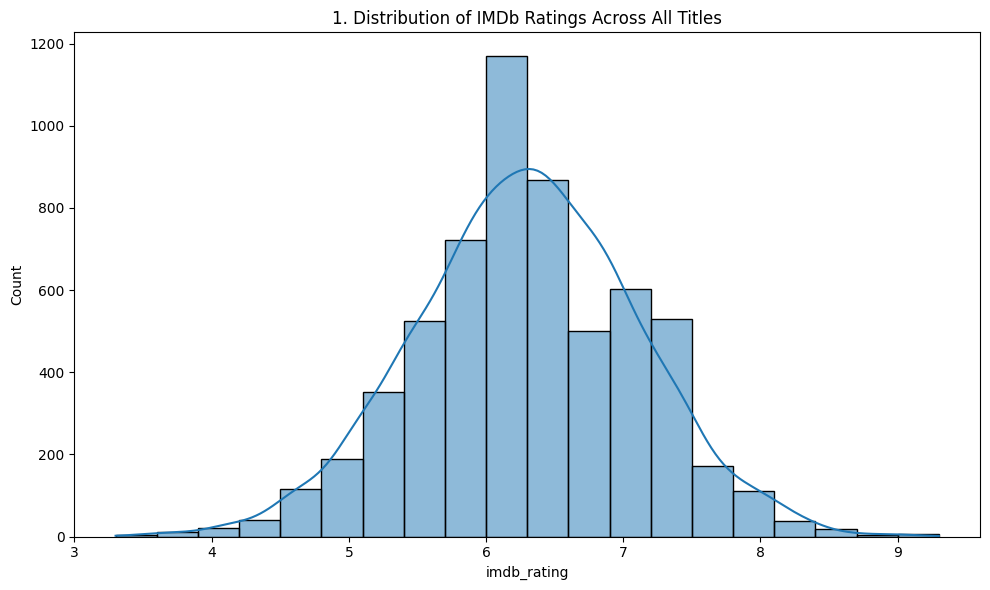

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='imdb_rating', kde=True, bins=20)
plt.title(f'{plot_no}. Distribution of IMDb Ratings Across All Titles')
show_fig()
plot_no += 1

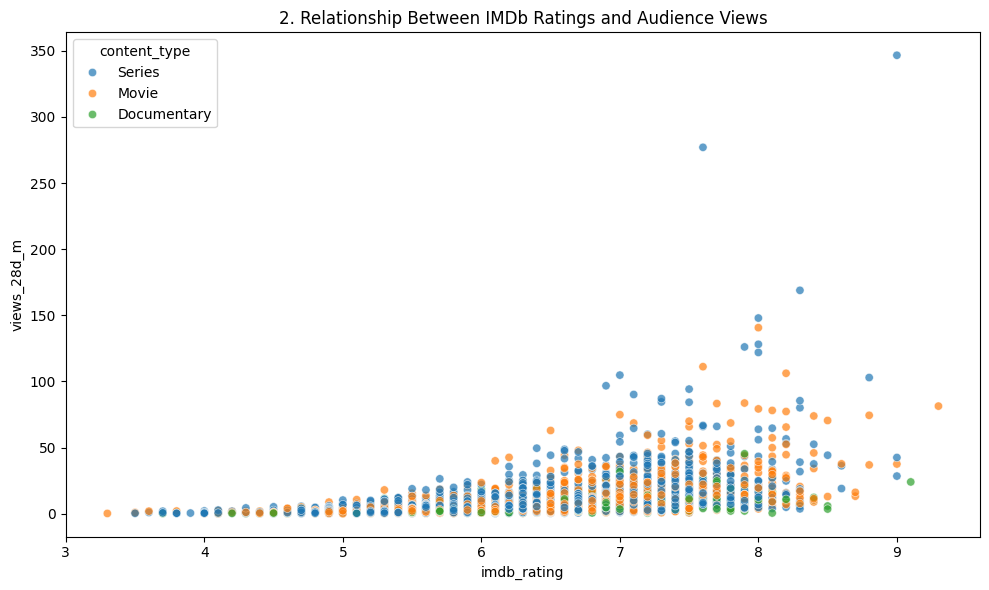

In [14]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='imdb_rating', y='views_28d_m', hue='content_type', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between IMDb Ratings and Audience Views')
show_fig()
plot_no += 1

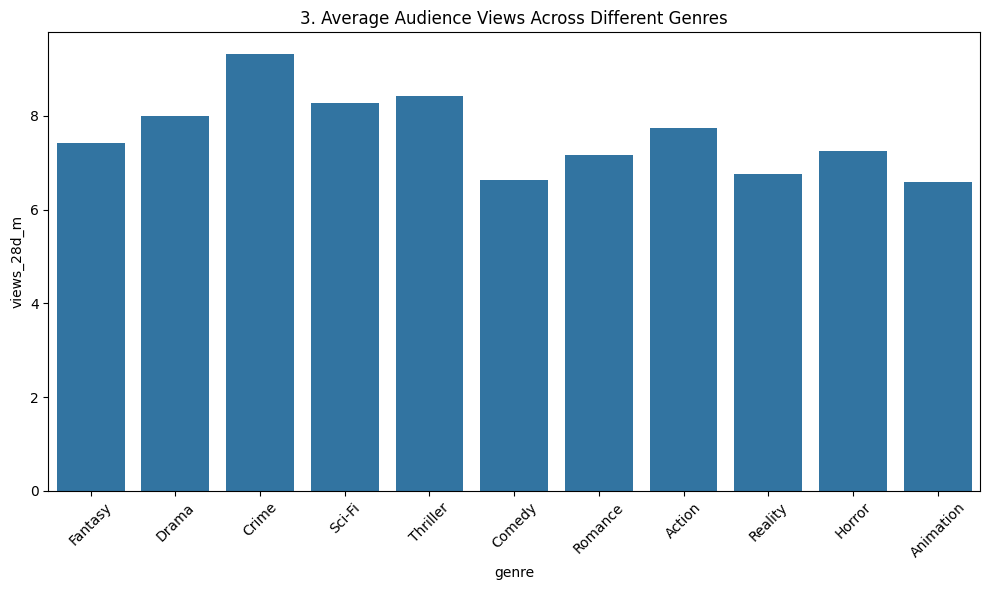

In [15]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='genre', y='views_28d_m', estimator='mean', errorbar=None)
plt.xticks(rotation=45)
plt.title(f'{plot_no}. Average Audience Views Across Different Genres')
show_fig()
plot_no += 1

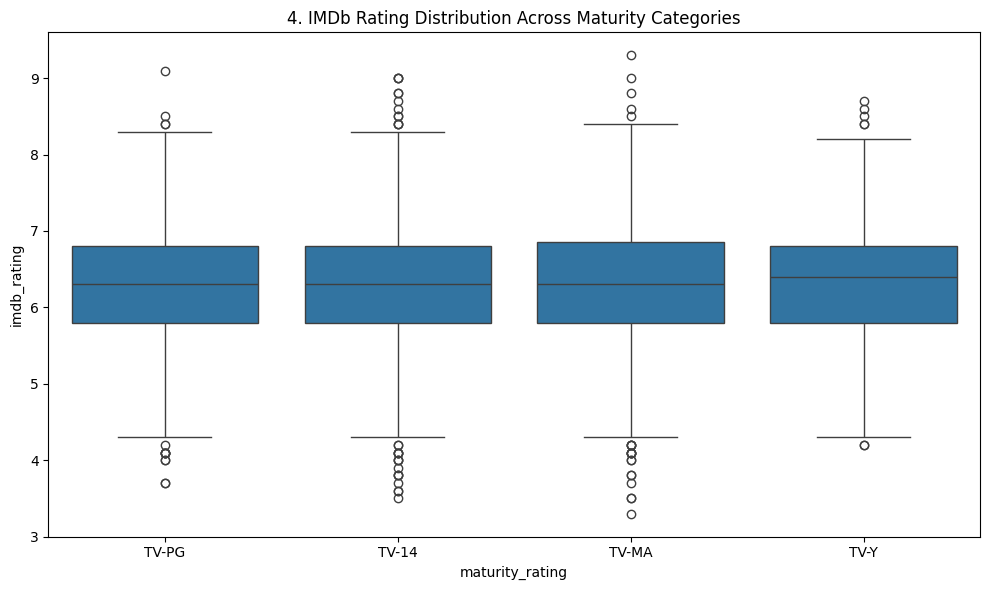

In [16]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='maturity_rating', y='imdb_rating')
plt.title(f'{plot_no}. IMDb Rating Distribution Across Maturity Categories')
show_fig()
plot_no += 1

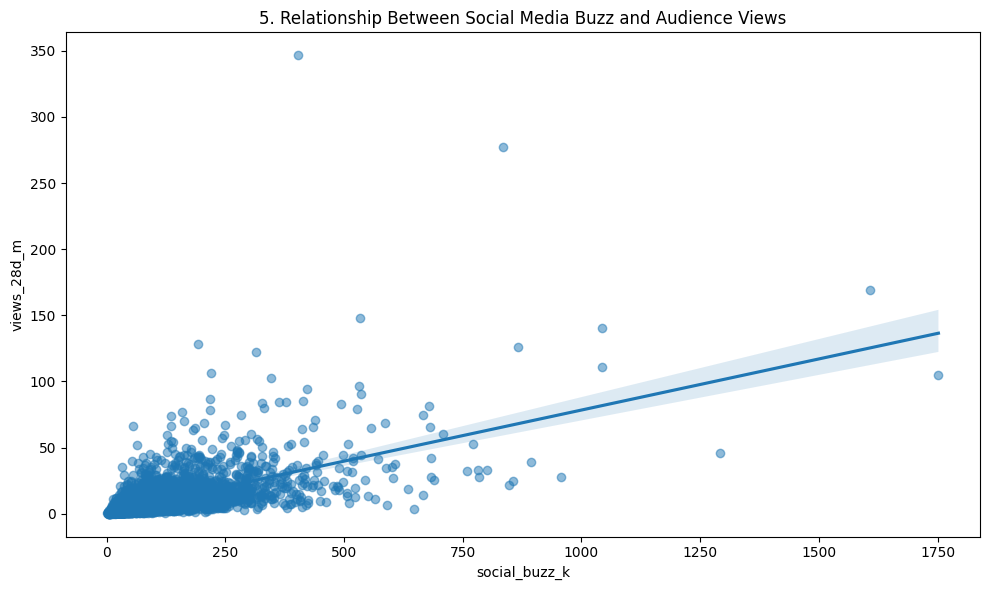

In [17]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='social_buzz_k', y='views_28d_m', scatter_kws={'alpha':0.5})
plt.title(f'{plot_no}. Relationship Between Social Media Buzz and Audience Views')
show_fig()
plot_no += 1

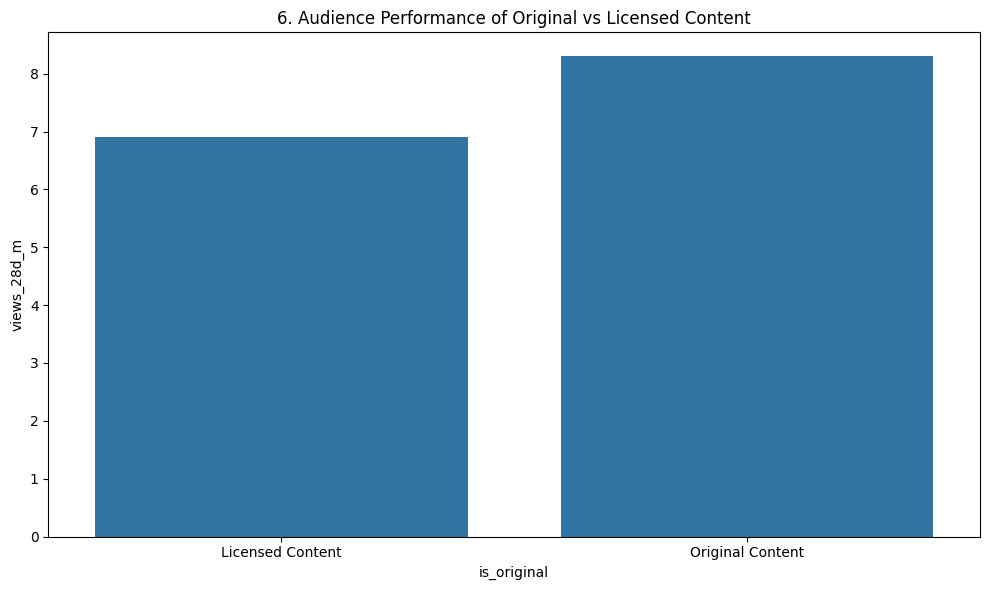

In [18]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='is_original', y='views_28d_m', errorbar=None)
plt.xticks([0,1], ['Licensed Content', 'Original Content'])
plt.title(f'{plot_no}. Audience Performance of Original vs Licensed Content')
show_fig()
plot_no += 1

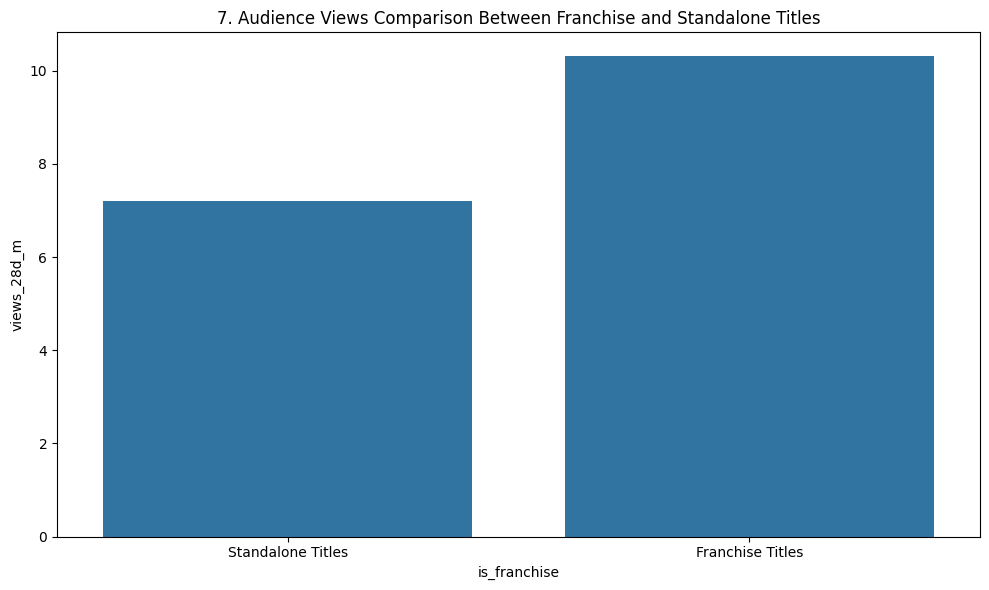

In [19]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='is_franchise', y='views_28d_m', errorbar=None)
plt.xticks([0,1], ['Standalone Titles', 'Franchise Titles'])
plt.title(f'{plot_no}. Audience Views Comparison Between Franchise and Standalone Titles')
show_fig()
plot_no += 1

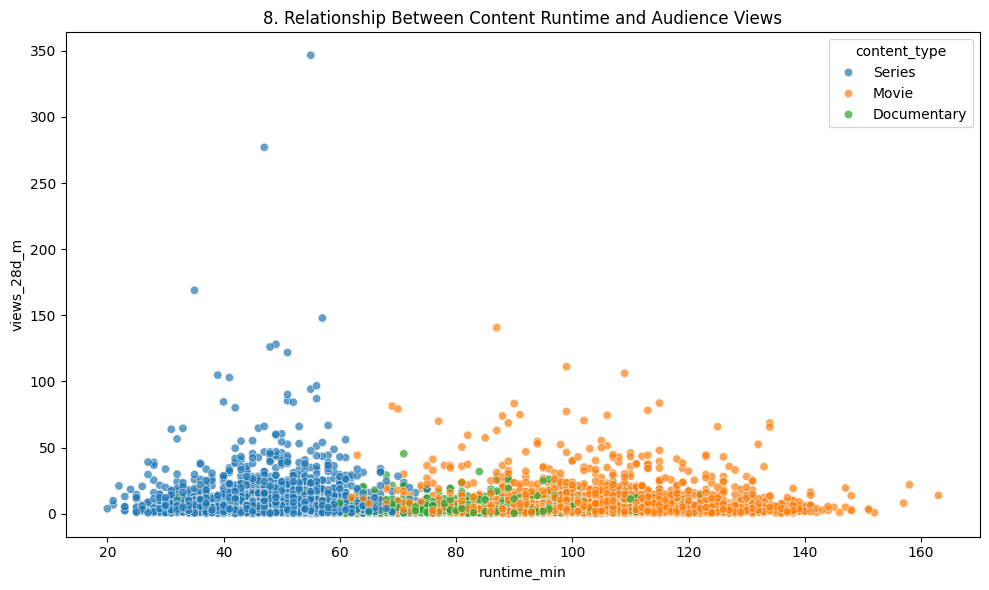

In [20]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='runtime_min', y='views_28d_m', hue='content_type', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Content Runtime and Audience Views')
show_fig()
plot_no += 1

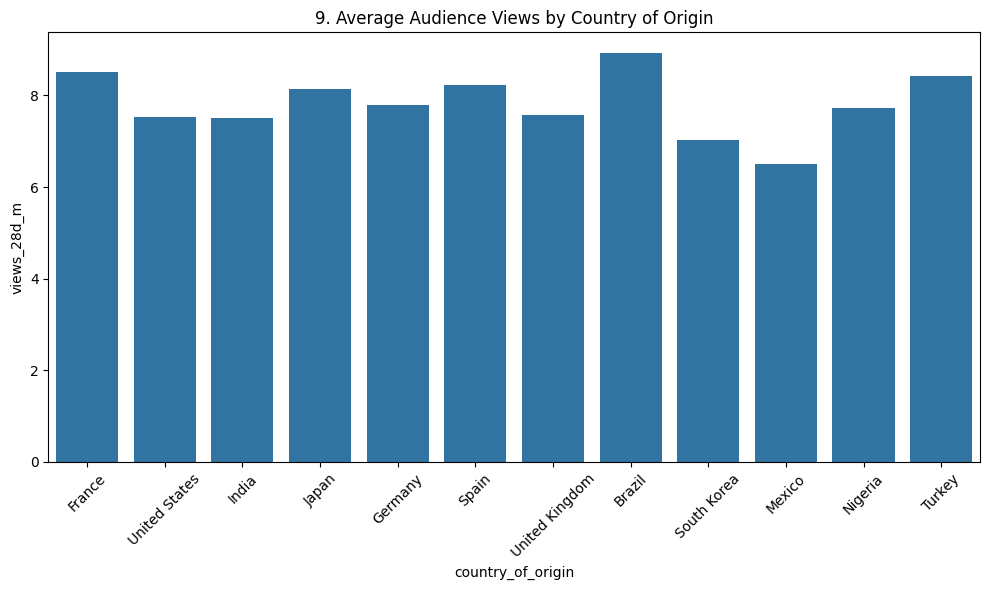

In [21]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='country_of_origin', y='views_28d_m', estimator='mean', errorbar=None)
plt.xticks(rotation=45)
plt.title(f'{plot_no}. Average Audience Views by Country of Origin')
show_fig()
plot_no += 1

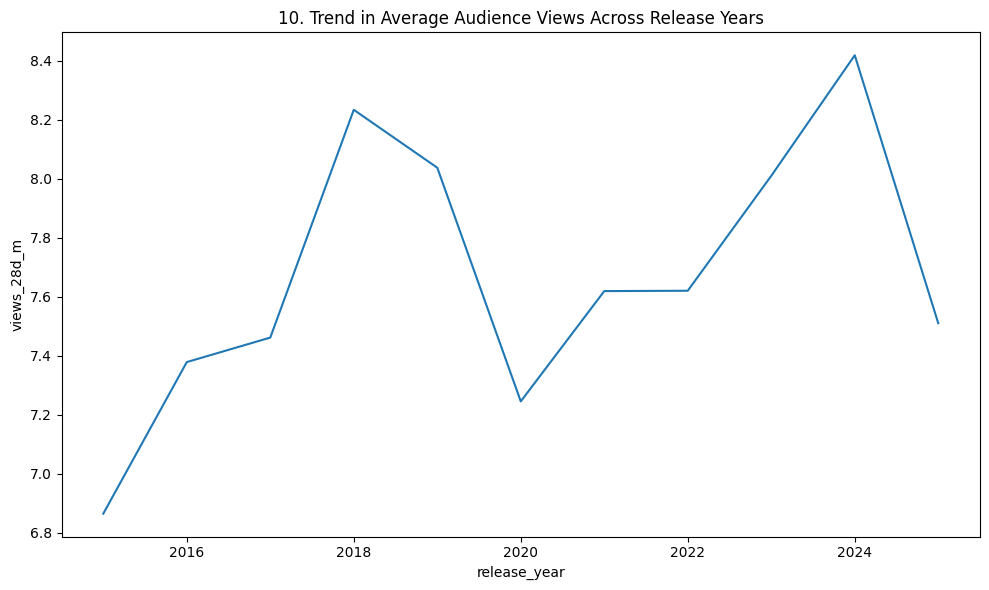

In [22]:
fig = plt.figure(figsize=(10,6))
sns.lineplot(data=df, x='release_year', y='views_28d_m', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Trend in Average Audience Views Across Release Years')
show_fig()
plot_no += 1

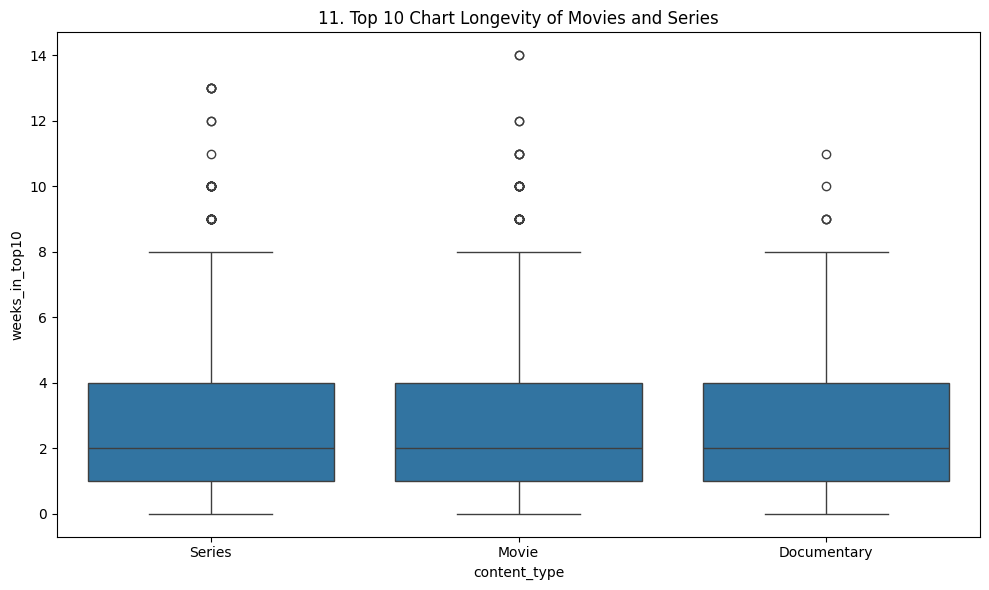

In [23]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='content_type', y='weeks_in_top10')
plt.title(f'{plot_no}. Top 10 Chart Longevity of Movies and Series')
show_fig()
plot_no += 1

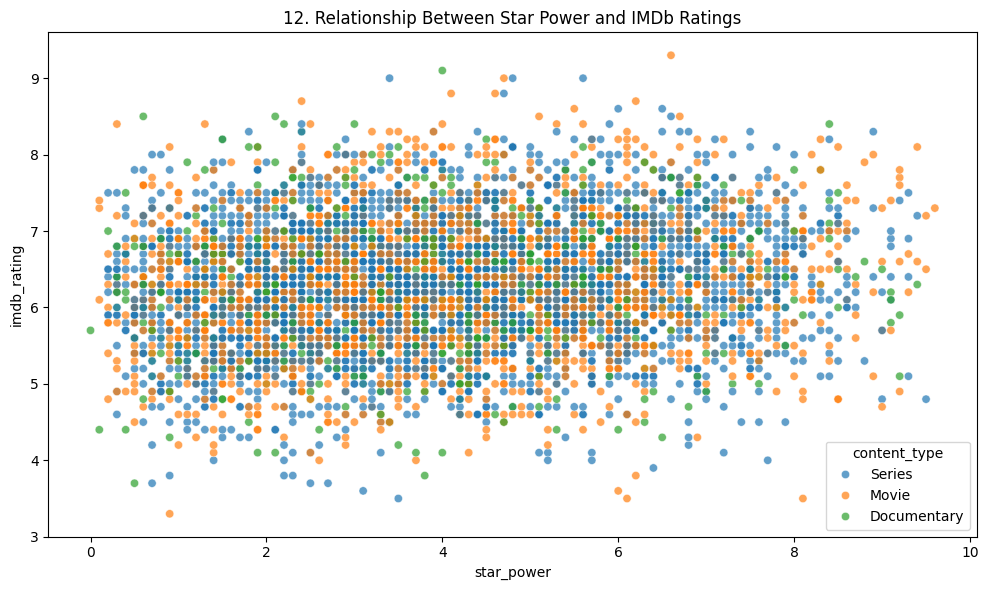

In [24]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='star_power', y='imdb_rating', hue='content_type', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Star Power and IMDb Ratings')
show_fig()
plot_no += 1

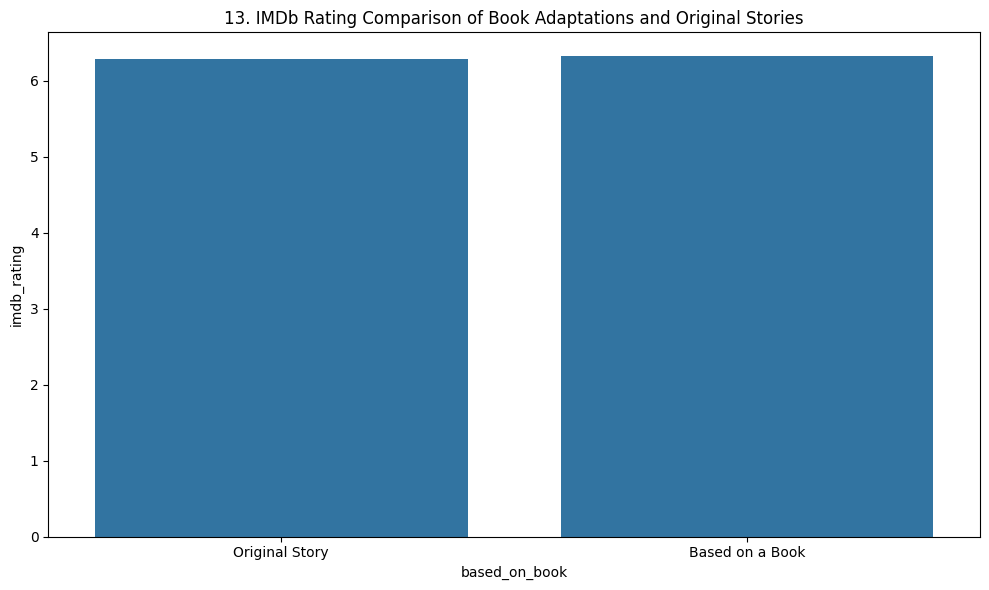

In [25]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='based_on_book', y='imdb_rating', errorbar=None)
plt.xticks([0,1], ['Original Story', 'Based on a Book'])
plt.title(f'{plot_no}. IMDb Rating Comparison of Book Adaptations and Original Stories')
show_fig()
plot_no += 1

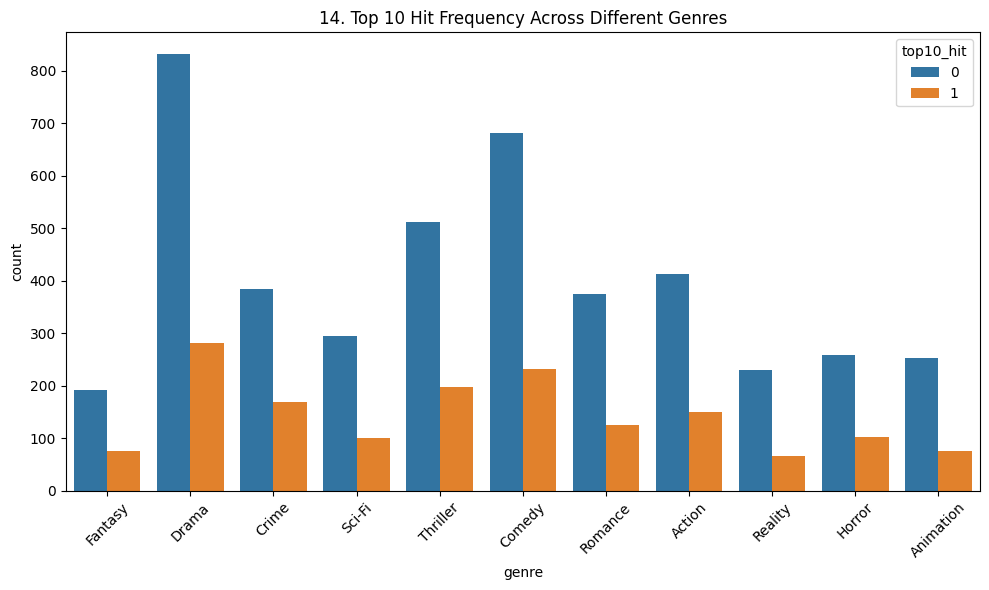

In [26]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='genre', hue='top10_hit')
plt.xticks(rotation=45)
plt.title(f'{plot_no}. Top 10 Hit Frequency Across Different Genres')
show_fig()
plot_no += 1

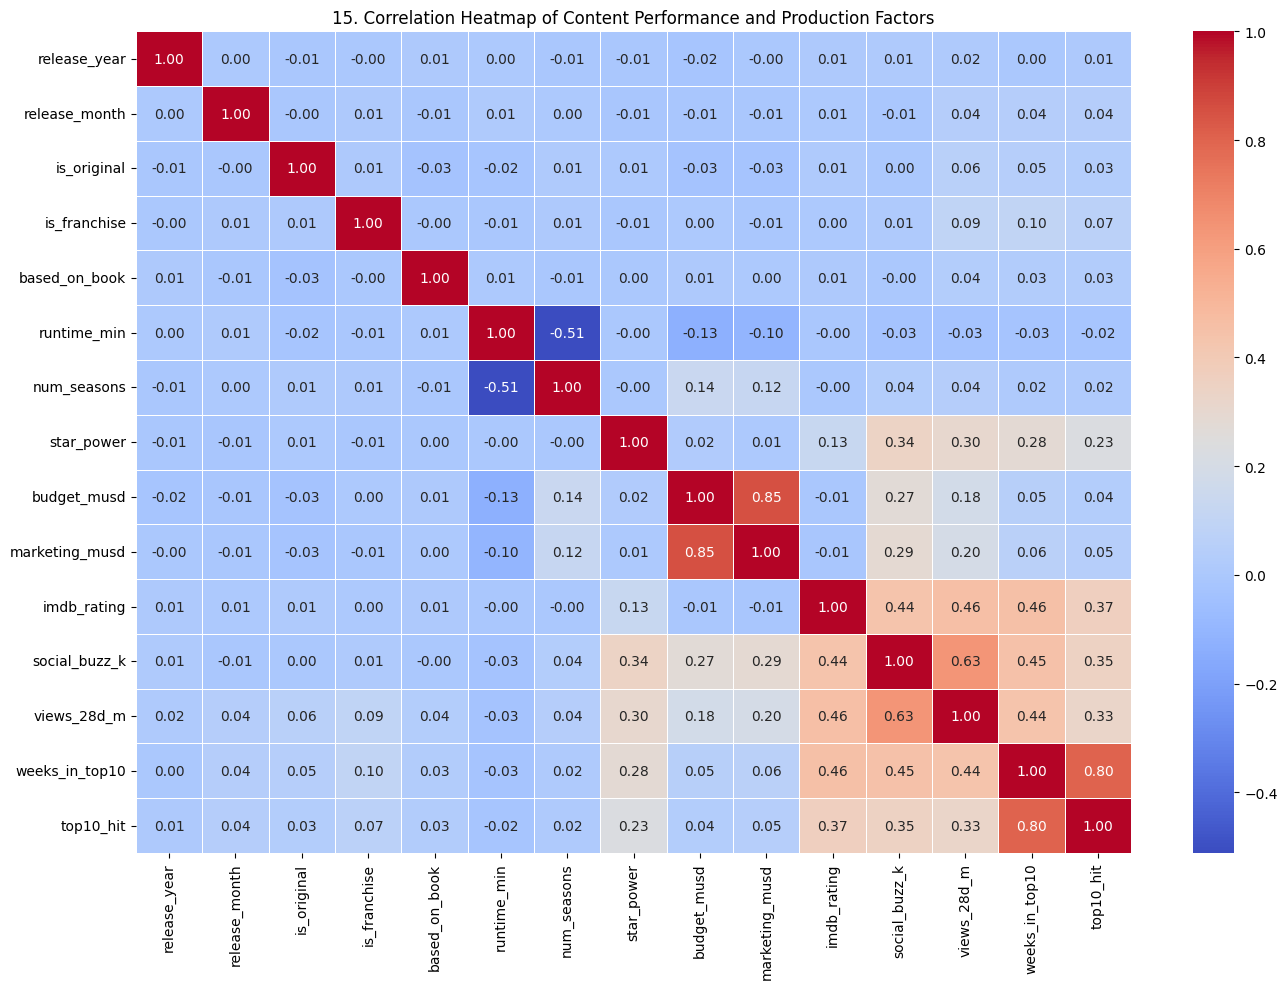

In [27]:
corr = df.select_dtypes(include='number').corr()

fig = plt.figure(figsize=(14,10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Content Performance and Production Factors')
show_fig()
plot_no += 1

# Model Training

## Select features and target

In [28]:
X = df.drop(columns=['title_id', 'title', 'top10_hit', 'weeks_in_top10', 'views_28d_m'])
y = df['top10_hit']

## Identify numerical and categorical columns

In [29]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

## Create numerical preprocessing

In [30]:
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

## Create categorical preprocessing

In [31]:
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

## Combine preprocessing

In [32]:
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

## Create ensemble classifier

In [33]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', VotingClassifier(estimators=[
        ('extra', ExtraTreesClassifier(n_estimators=300, max_depth=18, min_samples_leaf=2, class_weight='balanced', random_state=42)),
        ('hist', HistGradientBoostingClassifier(max_iter=250, learning_rate=0.06, max_leaf_nodes=20, l2_regularization=2.0, random_state=42))
    ], voting='soft'))
])

## Split training and testing data

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Train model

In [35]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Generate predictions

In [36]:
y_pred = model.predict(X_test)

## Evaluate model

In [37]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Model Accuracy: 77.5 %

Classification Report:

              precision    recall  f1-score   support

           0       0.80      0.92      0.86       885
           1       0.62      0.37      0.46       315

    accuracy                           0.78      1200
   macro avg       0.71      0.65      0.66      1200
weighted avg       0.76      0.78      0.75      1200



## Plot confusion matrix

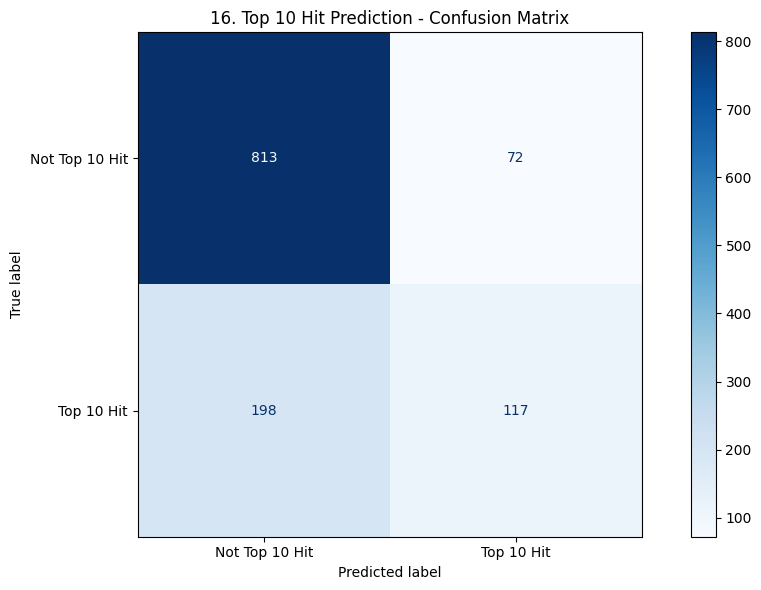

In [38]:
fig = plt.figure(figsize=(10,6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Not Top 10 Hit', 'Top 10 Hit'],
    cmap='Blues',
    ax=plt.gca()
)
plt.title(f'{plot_no}. Top 10 Hit Prediction - Confusion Matrix')
show_fig()